In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import urllib.request
import unicodedata
import re
import json

from torch.utils.data import Dataset, DataLoader
from collections import Counter

torch.manual_seed(0)
np.random.seed(0)

print("Biblioteki zaimportowane")


Biblioteki zaimportowane


In [5]:
from google.colab import files

# wgranie pliku Przedwiośnie
uploaded = files.upload()

nazwa_pliku = next(iter(uploaded))
tekst = uploaded[nazwa_pliku].decode("utf-8-sig")

print("Wczytano plik:", nazwa_pliku)
print("Długość tekstu:", len(tekst))
print()
print("Początek tekstu:")
print(tekst[:500])


Saving przedwiosnie.txt to przedwiosnie.txt
Wczytano plik: przedwiosnie.txt
Długość tekstu: 557532

Początek tekstu:
Stefan Żeromski

Przedwiośnie

ISBN 978-83-288-2967-1




Panu Konradowi Czarnockiemu
w przyjaznym upominku ofiarowuje ten utwórautor












Rodowód

Nie chodzi tutaj — u kaduka! — o herb ani o szeregi przodków podgolonych, z sarmackimi wąsami i przy karabelach — ani wydekoltowane prababki w fiokach. Ojciec i matka — otóż i cały rodowód, jak to jest u nas, w dziejach nowoczesnych ludzi bez wczoraj. Z konieczności wzmianka o jednym dziadku, z musu notatka o jednym je


In [6]:
# normalizacja Unicode
tekst = unicodedata.normalize("NFC", tekst)

# ujednolicenie końców linii
tekst = tekst.replace("\r\n", "\n").replace("\r", "\n")
tekst = tekst.replace("\xa0", " ")

# usunięcie nagłówka – początek właściwego tekstu
poczatek = tekst.find("\nRodowód\n")

if poczatek != -1:
    tekst = tekst[poczatek + 1:]

# usunięcie stopki Wolnych Lektur
koniec = tekst.find(
    "Ta lektura, podobnie jak tysiące innych"
)

if koniec != -1:
    tekst = tekst[:koniec]

tekst = tekst.rstrip(" \n-")

# usunięcie nadmiarowych pustych linii
tekst = re.sub(r"\n{3,}", "\n\n", tekst)

print("Długość po oczyszczeniu:", len(tekst))
print()
print("Fragment oczyszczonego tekstu:")
print(tekst[:500])

# sprawdzenie polskich znaków
polskie = "ąćęłńóśźżĄĆĘŁŃÓŚŹŻ"

print()
print("Polskie znaki w tekście:")
print([z for z in polskie if z in tekst])

assert len(tekst) > 1000

Długość po oczyszczeniu: 551364

Fragment oczyszczonego tekstu:
Rodowód

Nie chodzi tutaj — u kaduka! — o herb ani o szeregi przodków podgolonych, z sarmackimi wąsami i przy karabelach — ani wydekoltowane prababki w fiokach. Ojciec i matka — otóż i cały rodowód, jak to jest u nas, w dziejach nowoczesnych ludzi bez wczoraj. Z konieczności wzmianka o jednym dziadku, z musu notatka o jednym jedynym pradziadku. Chcemy uszanować nasyconą do pełna duchem i upodobaniem semickim awersję ludzi nowoczesnych do obciążania sobie pamięci wiadomościami, w którym kościele 

Polskie znaki w tekście:
['ą', 'ć', 'ę', 'ł', 'ń', 'ó', 'ś', 'ź', 'ż', 'Ł', 'Ó', 'Ś', 'Ź', 'Ż']


In [7]:
# podział danych na trening, walidację i test
n = len(tekst)

n_train = int(0.8 * n)
n_val = int(0.9 * n)

tekst_train = tekst[:n_train]
tekst_val = tekst[n_train:n_val]
tekst_test = tekst[n_val:]

zbiory = {
    "Trening": tekst_train,
    "Walidacja": tekst_val,
    "Test": tekst_test
}

print("PODZIAŁ KORPUSU")

for nazwa, fragment in zbiory.items():
    print(
        f"{nazwa}: {len(fragment)} znaków "
        f"({100 * len(fragment) / n:.2f}%)"
    )

assert len(tekst_train) + len(tekst_val) + len(tekst_test) == n


PODZIAŁ KORPUSU
Trening: 441091 znaków (80.00%)
Walidacja: 55136 znaków (10.00%)
Test: 55137 znaków (10.00%)


In [8]:
# słownik na podstawie treningu
znaki = sorted(set(tekst_train))
stoi = {z: i + 1 for i, z in enumerate(znaki)}
itos = {i: z for z, i in stoi.items()}

# znak nieznany
UNK = 0
itos[UNK] = "<UNK>"
V = len(itos)
def enc(s):
    return [stoi.get(z, UNK) for z in s]
def dec(ids):
    return "".join(itos[int(i)] for i in ids)

print("Rozmiar słownika:", V)
print("Znaki treningowe:", repr("".join(znaki)))

# sprawdzenie kodowania i dekodowania
fragment = tekst_train[:100]
zakodowany = enc(fragment)
odkodowany = dec(zakodowany)

print("\nFragment oryginalny:", repr(fragment))
print("Zakodowany:", zakodowany)
print("Odkodowany:", repr(odkodowany))

assert fragment == odkodowany

print("\nKodowanie i dekodowanie poprawne")


Rozmiar słownika: 97
Znaki treningowe: "\n !'()*,-.012345789:;?ABCDEFGHIJKLMNOPRSTUVWZabcdefghijklmnopqrstuvwyz«»ÓçèéîóôąćęŁłńŚśŹźŻż–—”„…"

Fragment oryginalny: 'Rodowód\n\nNie chodzi tutaj — u kaduka! — o herb ani o szeregi przodków podgolonych, z sarmackimi wąsa'
Zakodowany: [39, 60, 49, 60, 68, 78, 49, 1, 1, 36, 54, 50, 2, 48, 53, 60, 49, 70, 54, 2, 65, 66, 65, 46, 55, 2, 93, 2, 66, 2, 56, 46, 49, 66, 56, 46, 3, 2, 93, 2, 60, 2, 53, 50, 63, 47, 2, 46, 59, 54, 2, 60, 2, 64, 70, 50, 63, 50, 52, 54, 2, 61, 63, 70, 60, 49, 56, 78, 68, 2, 61, 60, 49, 52, 60, 57, 60, 59, 69, 48, 53, 8, 2, 70, 2, 64, 46, 63, 58, 46, 48, 56, 54, 58, 54, 2, 68, 80, 64, 46]
Odkodowany: 'Rodowód\n\nNie chodzi tutaj — u kaduka! — o herb ani o szeregi przodków podgolonych, z sarmackimi wąsa'

Kodowanie i dekodowanie poprawne


In [9]:
print("SPRAWDZENIE NIEZNANYCH ZNAKÓW")

for nazwa, fragment in zbiory.items():
    nieznane = sorted(set(fragment) - set(znaki))
    liczba_unk = sum(
        1 for z in fragment if z not in stoi
    )

    print(f"\n{nazwa}")
    print("Nieznane znaki:", nieznane)
    print("Liczba wystąpień UNK:", liczba_unk)

SPRAWDZENIE NIEZNANYCH ZNAKÓW

Trening
Nieznane znaki: []
Liczba wystąpień UNK: 0

Walidacja
Nieznane znaki: ['6', 'x']
Liczba wystąpień UNK: 4

Test
Nieznane znaki: ['%', '6', 'X', 'x']
Liczba wystąpień UNK: 4


In [10]:
dane_train = np.array(
    enc(tekst_train), dtype=np.int64
)

dane_val = np.array(
    enc(tekst_val), dtype=np.int64
)

dane_test = np.array(
    enc(tekst_test), dtype=np.int64
)

dane_zbiorow = {
    "Trening": dane_train,
    "Walidacja": dane_val,
    "Test": dane_test
}

for nazwa, dane in dane_zbiorow.items():
    print(nazwa, dane.shape)

Trening (441091,)
Walidacja (55136,)
Test (55137,)


In [11]:
class DatasetZnakowy(Dataset):
    def __init__(self, dane, sekw, krok=1):
        self.dane = dane
        self.sekw = sekw
        self.krok = krok
    def __len__(self):
        n = len(self.dane)
        return max(0, (n - self.sekw - 1) // self.krok + 1)
    def __getitem__(self, i):
        start = i * self.krok

        x = self.dane[start:start + self.sekw]
        y = self.dane[start + 1:start + self.sekw + 1]

        return (
            torch.tensor(x, dtype=torch.long),
            torch.tensor(y, dtype=torch.long)
        )

print("Klasa DatasetZnakowy gotowa")

Klasa DatasetZnakowy gotowa


In [12]:
SEKW = 40
BATCH = 32
KROK = 1

datasety = {}
loadery = {}

for nazwa, dane in dane_zbiorow.items():
    ds = DatasetZnakowy(
        dane, SEKW, KROK
    )
    dl = DataLoader(
        ds,
        batch_size=BATCH,
        shuffle=(nazwa == "Trening"),
        drop_last=(nazwa == "Trening")
    )
    datasety[nazwa] = ds
    loadery[nazwa] = dl

    print(f"\n{nazwa}")
    print("Liczba par:", len(ds))
    print("Liczba batchy:", len(dl))


Trening
Liczba par: 441051
Liczba batchy: 13782

Walidacja
Liczba par: 55096
Liczba batchy: 1722

Test
Liczba par: 55097
Liczba batchy: 1722


In [13]:
for nazwa in zbiory:
    ds = datasety[nazwa]
    dl = loadery[nazwa]
    fragment = zbiory[nazwa]
    assert len(dl) > 0
    xb, yb = next(iter(dl))

    print(f"\n===== {nazwa} =====")
    print("Batch X:", xb.shape)
    print("Batch Y:", yb.shape)

    # sprawdzenie wymiarów i typu
    assert xb.shape == yb.shape
    assert xb.shape[1] == SEKW
    assert xb.dtype == torch.int64
    assert yb.dtype == torch.int64

    # sprawdzenie zakresu identyfikatorów
    assert xb.min().item() >= 0
    assert xb.max().item() < V
    assert yb.min().item() >= 0
    assert yb.max().item() < V

    # kontrola jednego przykładu z batcha
    x = xb[0].tolist()
    y = yb[0].tolist()

    print("\nWejście z batcha:")
    print(repr(dec(x)))

    print("Cel z batcha:")
    print(repr(dec(y)))

    assert x[1:] == y[:-1]

    # sprawdzenie pierwszej pary z Dataset
    x0, y0 = ds[0]

    assert x0.tolist() == enc(fragment[:SEKW])
    assert y0.tolist() == enc(fragment[1:SEKW + 1])

    print("\nPierwsza para względem tekstu:")
    print("Wejście:", repr(dec(x0.tolist())))
    print("Cel:", repr(dec(y0.tolist())))
    print("Przesunięcie poprawne")
    print("Kontrola batcha zakończona")



===== Trening =====
Batch X: torch.Size([32, 40])
Batch Y: torch.Size([32, 40])

Wejście z batcha:
'ia. Przypatrzył się jej pewnego razu pil'
Cel z batcha:
'a. Przypatrzył się jej pewnego razu piln'

Pierwsza para względem tekstu:
Wejście: 'Rodowód\n\nNie chodzi tutaj — u kaduka! — '
Cel: 'odowód\n\nNie chodzi tutaj — u kaduka! — o'
Przesunięcie poprawne
Kontrola batcha zakończona

===== Walidacja =====
Batch X: torch.Size([32, 40])
Batch Y: torch.Size([32, 40])

Wejście z batcha:
'gi?\n\n— Ten drugi — to Stanisław Krzemińs'
Cel z batcha:
'i?\n\n— Ten drugi — to Stanisław Krzemińsk'

Pierwsza para względem tekstu:
Wejście: 'gi?\n\n— Ten drugi — to Stanisław Krzemińs'
Cel: 'i?\n\n— Ten drugi — to Stanisław Krzemińsk'
Przesunięcie poprawne
Kontrola batcha zakończona

===== Test =====
Batch X: torch.Size([32, 40])
Batch Y: torch.Size([32, 40])

Wejście z batcha:
'paltot starannie złożony, z ładną jedwab'
Cel z batcha:
'altot starannie złożony, z ładną jedwabn'

Pierwsza para względem tek

In [14]:
print("STATYSTYKI ZBIORÓW\n")

print(
    f"{'Zbiór':12} "
    f"{'Znaki':>10} "
    f"{'Udział %':>10} "
    f"{'Różne':>8} "
    f"{'Pary':>10} "
    f"{'Batche':>10}"
)
for nazwa, fragment in zbiory.items():
    ds = datasety[nazwa]
    dl = loadery[nazwa]
    liczba = len(fragment)
    udzial = 100 * liczba / len(tekst)
    rozne = len(set(fragment))

    print(
        f"{nazwa:12} "
        f"{liczba:10d} "
        f"{udzial:10.2f} "
        f"{rozne:8d} "
        f"{len(ds):10d} "
        f"{len(dl):10d}"
    )

STATYSTYKI ZBIORÓW

Zbiór             Znaki   Udział %    Różne       Pary     Batche
Trening          441091      80.00       96     441051      13782
Walidacja         55136      10.00       83      55096       1722
Test              55137      10.00       85      55097       1722


In [15]:
okna = [20, 40, 80]
wyniki_okien = {}

print("WPŁYW DŁUGOŚCI OKNA\n")

print(
    f"{'SEKW':>6} "
    f"{'Trening':>12} "
    f"{'Walidacja':>12} "
    f"{'Test':>12}"
)
for sekw in okna:
    wyniki_okien[sekw] = {}
    for nazwa, dane in dane_zbiorow.items():
        ds = DatasetZnakowy(
            dane, sekw, krok=KROK
        )
        wyniki_okien[sekw][nazwa] = len(ds)

    print(
        f"{sekw:6d} "
        f"{wyniki_okien[sekw]['Trening']:12d} "
        f"{wyniki_okien[sekw]['Walidacja']:12d} "
        f"{wyniki_okien[sekw]['Test']:12d}"
    )


WPŁYW DŁUGOŚCI OKNA

  SEKW      Trening    Walidacja         Test
    20       441071        55116        55117
    40       441051        55096        55097
    80       441011        55056        55057


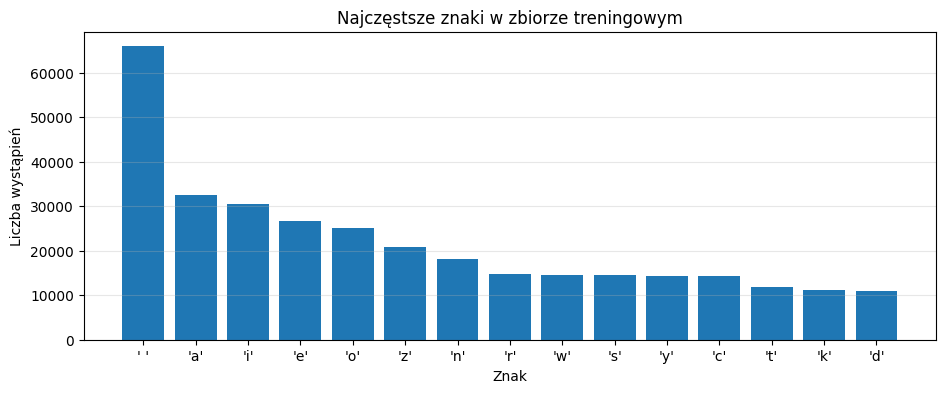

In [16]:
czestosci = Counter(tekst_train)

najczestsze = czestosci.most_common(15)

etykiety = [repr(z) for z, n in najczestsze]
liczby = [n for z, n in najczestsze]

plt.figure(figsize=(11, 4))

plt.bar(etykiety, liczby)

plt.title("Najczęstsze znaki w zbiorze treningowym")
plt.xlabel("Znak")
plt.ylabel("Liczba wystąpień")

plt.grid(axis="y", alpha=0.3)
plt.show()

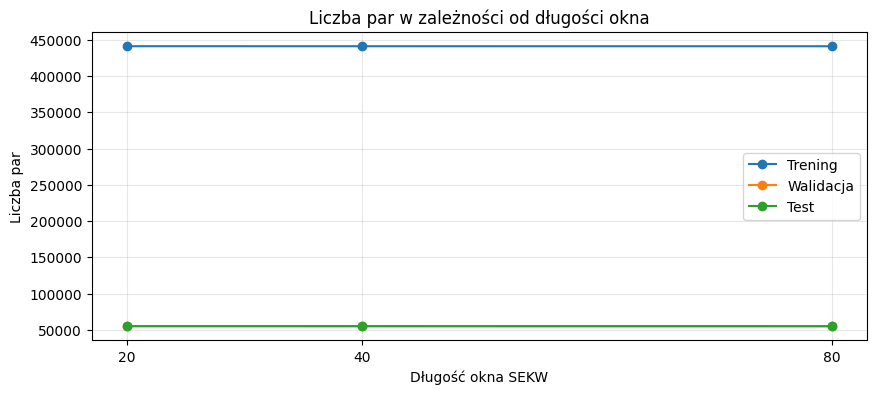

In [17]:
plt.figure(figsize=(10, 4))

for nazwa in zbiory:
    liczby = [
        wyniki_okien[sekw][nazwa]
        for sekw in okna
    ]
    plt.plot(
        okna,
        liczby,
        marker="o",
        label=nazwa
    )

plt.title("Liczba par w zależności od długości okna")
plt.xlabel("Długość okna SEKW")
plt.ylabel("Liczba par")

plt.xticks(okna)
plt.grid(alpha=0.3)
plt.legend()
plt.show()


In [18]:
# zapis oczyszczonego korpusu
with open("przedwiosnie_clean.txt", "w", encoding="utf-8") as f:
    f.write(tekst)

# zapis trzech zbiorów
pliki = {
    "train": tekst_train,
    "val": tekst_val,
    "test": tekst_test
}
for nazwa, fragment in pliki.items():
    with open(
        f"przedwiosnie_{nazwa}.txt",
        "w",
        encoding="utf-8"
    ) as f:
        f.write(fragment)

# zapis słownika i parametrów
konfiguracja = {
    "zrodlo": url,
    "slownik": stoi,
    "unk_id": UNK,
    "V": V,
    "SEKW": SEKW,
    "BATCH": BATCH,
    "KROK": KROK,
    "podzial": [0.8, 0.1, 0.1]
}
with open(
    "przedwiosnie_konfiguracja.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        konfiguracja,
        f,
        ensure_ascii=False,
        indent=2
    )

print("Zapisano dane do Laboratorium 7")

Zapisano dane do Laboratorium 7
